# Phase 2 · Preprocessing & Data Cleaning
### Làm sạch, chia tập chống rò rỉ, xử lý lệch/ngoại lai, chuẩn hóa và cân bằng dữ liệu

| 5W1H | Nội dung |
|---|---|
| **What** | Biến dữ liệu thô thành các tập **Train / Validation / Test (60/20/20)** sạch, đã chuẩn hóa, sẵn sàng cho Phase 3–4. |
| **Why** | Phase 1 phát hiện 5 vấn đề: (1) trùng lặp gần và nhãn mâu thuẫn, (2) shortcut định dạng, (3) phân phối lệch nặng và đuôi dày, (4) dữ liệu phân cụm theo domain, (5) mất cân bằng ~3.6 : 1. Mỗi mục dưới đây xử lý một vấn đề. |
| **Where** | Đầu vào: `data/raw/phishing_site_urls.csv`. Đầu ra: `artifacts/data/*.parquet`, `*.npz`, `artifacts/transformers/*.joblib`, `artifacts/reports/phase2_*.{csv,json}`. |
| **How** | Chuẩn hóa URL → khử trùng lặp → chia phân tầng theo nhóm domain → trích xuất đặc trưng → Winsorizing + Yeo-Johnson + scaling (**fit chỉ trên Train**) → Target Encoding cho TLD → TF-IDF → class weights → đối chiếu Trước/Sau → lưu xuống đĩa. |

> 🔒 **Nguyên tắc chống Data Leakage:** mọi transformer có tham số học từ dữ liệu (biên cắt, λ Yeo-Johnson, mean/std, IQR, target encoding, vocabulary TF-IDF) đều được `fit` **chỉ trên Train**, sau đó dùng `transform` cho Validation và Test.

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path


def _find_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data' / 'raw' / 'phishing_site_urls.csv').exists():
            return p
    raise FileNotFoundError('Không tìm thấy thư mục gốc dự án.')


ROOT = _find_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse, stats

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, RobustScaler, StandardScaler, TargetEncoder
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, recall_score, precision_score

from src.phishing_ml.config import (RAW_PATH, DATA_DIR, TRANSFORMER_DIR, REPORT_DIR, RANDOM_STATE, PALETTE,
                                    ensure_dirs, seed_everything)
from src.phishing_ml.features import normalize_url, split_components, host_parts, build_feature_frame
from src.phishing_ml.preprocessing import IQRClipper

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=RuntimeWarning)
seed_everything()
ensure_dirs()
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
pd.set_option('display.max_columns', 40)
SPLITS = ['train', 'val', 'test']
print(f'Project root: {ROOT}')

Project root: /Users/buiquanghuy/Documents/phishing-url-detection


## 1. Làm sạch: chuẩn hóa URL, khử trùng lặp, loại nhãn mâu thuẫn

**5-Whys: vì sao phải chuẩn hóa trước khi khử trùng lặp?**
1. *Vì sao mô hình cũ chấm `google.com` là phishing 96.8%?* Vì nó học được rằng "không có `/` ⇒ phishing".
2. *Vì sao học được điều đó?* Vì trong dataset, URL hợp lệ hầu như luôn có `/` cuối, còn URL phishing thì không, đây là **artefact của quá trình thu thập**.
3. *Vì sao artefact này còn tồn tại?* Vì code cũ khử trùng lặp theo chuỗi **nguyên văn**, nên `a.com/` và `a.com` bị coi là hai URL khác nhau.
4. *Vì sao điều này nguy hiểm khi triển khai?* Vì URL thực tế từ trình duyệt hoặc email luôn có scheme và định dạng tùy ý, tạo ra **train/serve skew**.
5. **Gốc rễ:** thiếu một hàm chuẩn hóa **dùng chung** cho train và inference. Giải pháp là `normalize_url()` (bỏ scheme, `www.`, `/` cuối, viết thường host), áp dụng **trước** mọi bước khác.

In [2]:
raw = pd.read_csv(RAW_PATH).rename(columns={'URL': 'url', 'Label': 'label_text'})
steps = [('Dữ liệu thô', len(raw))]

raw = raw.dropna(subset=['url', 'label_text'])
raw['url'] = raw['url'].astype(str)
raw['label'] = raw['label_text'].map({'bad': 1, 'good': 0}).astype(int)
steps.append(('Sau dropna', len(raw)))

raw['url_norm'] = raw['url'].map(normalize_url)
raw = raw[raw['url_norm'].str.len() > 0]
steps.append(('Sau loại URL rỗng', len(raw)))

n_labels = raw.groupby('url_norm')['label'].transform('nunique')
n_conflict_urls = raw.loc[n_labels > 1, 'url_norm'].nunique()
raw = raw[n_labels == 1]
steps.append((f'Sau loại {n_conflict_urls} URL chuẩn hóa mâu thuẫn nhãn', len(raw)))

df = raw.drop_duplicates(subset='url_norm').drop(columns='label_text').reset_index(drop=True)
steps.append(('Sau khử trùng lặp theo URL chuẩn hóa', len(df)))

cleaning = pd.DataFrame(steps, columns=['Bước', 'Số dòng'])
cleaning['Bị loại'] = (-cleaning['Số dòng'].diff()).fillna(0).astype(int)
cleaning['% còn lại'] = cleaning['Số dòng'] / cleaning['Số dòng'].iloc[0] * 100
display(cleaning)
cleaning.to_csv(REPORT_DIR / 'phase2_cleaning_steps.csv', index=False)

,Bước,Số dòng,Bị loại,% còn lại
0,Dữ liệu thô,549346,0,100.0000
1,Sau dropna,549346,0,100.0000
2,Sau loại URL rỗng,549346,0,100.0000
3,Sau loại 2 URL chuẩn hóa mâu thuẫn nhãn,549340,6,99.9989
4,Sau khử trùng lặp theo URL chuẩn hóa,501550,47790,91.2995


## 2. Tách thành phần URL và Registered Domain

`registered_domain` (eTLD+1 theo Public Suffix List, ví dụ `bbc.co.uk`) là **khóa nhóm** để chia tập. `tld` là biến phân loại đầu vào. Các host được tính **một lần cho mỗi host duy nhất** để tăng tốc.

In [3]:
t0 = time.time()
comps = [split_components(u) for u in df['url_norm']]
df['host'] = [c[0] for c in comps]
host_info = {h: host_parts(h) for h in df['host'].unique()}
df['registered_domain'] = df['host'].map(lambda h: host_info[h][3])
print(f'{len(host_info):,} host → {df["registered_domain"].nunique():,} registered domain ({time.time() - t0:.1f}s)')
display(df.sample(5, random_state=RANDOM_STATE)[['url', 'url_norm', 'host', 'registered_domain', 'label']])

187,611 host → 151,535 registered domain (2.7s)


,url,url_norm,host,registered_domain,label
454786,wolf.org/wolves/enewsletter/email_sign.asp,wolf.org/wolves/enewsletter/email_sign.asp,wolf.org,wolf.org,0
272516,arenamaps.com/arenas/2639.htm,arenamaps.com/arenas/2639.htm,arenamaps.com,arenamaps.com,0
41711,blog.escoladoempreendedor.com/wp-includes/js/s...,blog.escoladoempreendedor.com/wp-includes/js/s...,blog.escoladoempreendedor.com,escoladoempreendedor.com,1
48214,www.bluerockit.com/home.shtml,bluerockit.com/home.shtml,bluerockit.com,bluerockit.com,0
417609,scribd.com/doc/15490973/Web-Mapping-Illustrate...,scribd.com/doc/15490973/Web-Mapping-Illustrate...,scribd.com,scribd.com,0


## 3. Chia tập Train / Validation / Test = 60 / 20 / 20

**Vì sao không dùng `train_test_split(stratify=y)` thông thường?** Vì nếu chia ngẫu nhiên theo dòng, URL của cùng một domain sẽ nằm ở cả train và test. Khi đó mô hình được thưởng điểm vì **nhớ domain**, không phải vì phát hiện được phishing. Ô code dưới đây **đo trực tiếp** mức rò rỉ đó.

**Giải pháp:** `StratifiedGroupKFold(n_splits=5)`, trong đó *stratified* giữ tỉ lệ nhãn và *group* đảm bảo mỗi domain chỉ nằm trong **một** tập. Năm fold rời nhau, mỗi fold khoảng 20% dữ liệu:
- fold 0 → **Test (20%)**, fold 1 → **Validation (20%)**, fold 2 + 3 + 4 → **Train (60%)**.

In [4]:
y_all = df['label'].to_numpy()
groups = df['registered_domain'].to_numpy()

# (a) Đo rò rỉ nếu chia ngẫu nhiên kiểu cũ
tr_naive, te_naive = train_test_split(np.arange(len(df)), test_size=0.2, stratify=y_all, random_state=RANDOM_STATE)
leak_rate = np.isin(groups[te_naive], np.unique(groups[tr_naive])).mean()
print(f'Chia ngẫu nhiên (kiểu cũ): {leak_rate:.1%} URL test có domain đã xuất hiện trong train → RÒ RỈ')

# (b) Chia phân tầng theo nhóm domain
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fold_parts = [part for _, part in sgkf.split(np.zeros(len(df)), y_all, groups)]
split_idx = {'test': np.sort(fold_parts[0]), 'val': np.sort(fold_parts[1]),
             'train': np.sort(np.concatenate(fold_parts[2:]))}

# Kiểm tra tính toàn vẹn
assert sum(len(v) for v in split_idx.values()) == len(df)
assert not set(split_idx['train']) & set(split_idx['test']) and not set(split_idx['train']) & set(split_idx['val'])
dom_sets = {k: set(groups[v]) for k, v in split_idx.items()}
assert not (dom_sets['train'] & dom_sets['val']) and not (dom_sets['train'] & dom_sets['test']) \
    and not (dom_sets['val'] & dom_sets['test']), 'Rò rỉ domain!'
print('✅ Ba tập rời nhau cả về URL lẫn registered domain.')

df['split'] = ''
for k, v in split_idx.items():
    df.loc[v, 'split'] = k

Chia ngẫu nhiên (kiểu cũ): 76.1% URL test có domain đã xuất hiện trong train → RÒ RỈ


✅ Ba tập rời nhau cả về URL lẫn registered domain.


,Số URL,Tỉ lệ (%),Số domain,Legitimate,Phishing,% Phishing
train,"300,928",60.00,"90,938","235,721","65,207",21.669
val,"100,315",20.00,"30,274","78,576","21,739",21.671
test,"100,307",20.00,"30,323","78,572","21,735",21.668


Kiểm định χ² đồng nhất tỉ lệ nhãn giữa 3 tập: χ² = 0.000, df = 2, p = 1.000, Cramér's V = 0.00002
→ Không có khác biệt có ý nghĩa: tỉ lệ nhãn đồng đều giữa các tập.


KS(url_len): train vs val: D = 0.0611


KS(url_len): train vs test: D = 0.0452


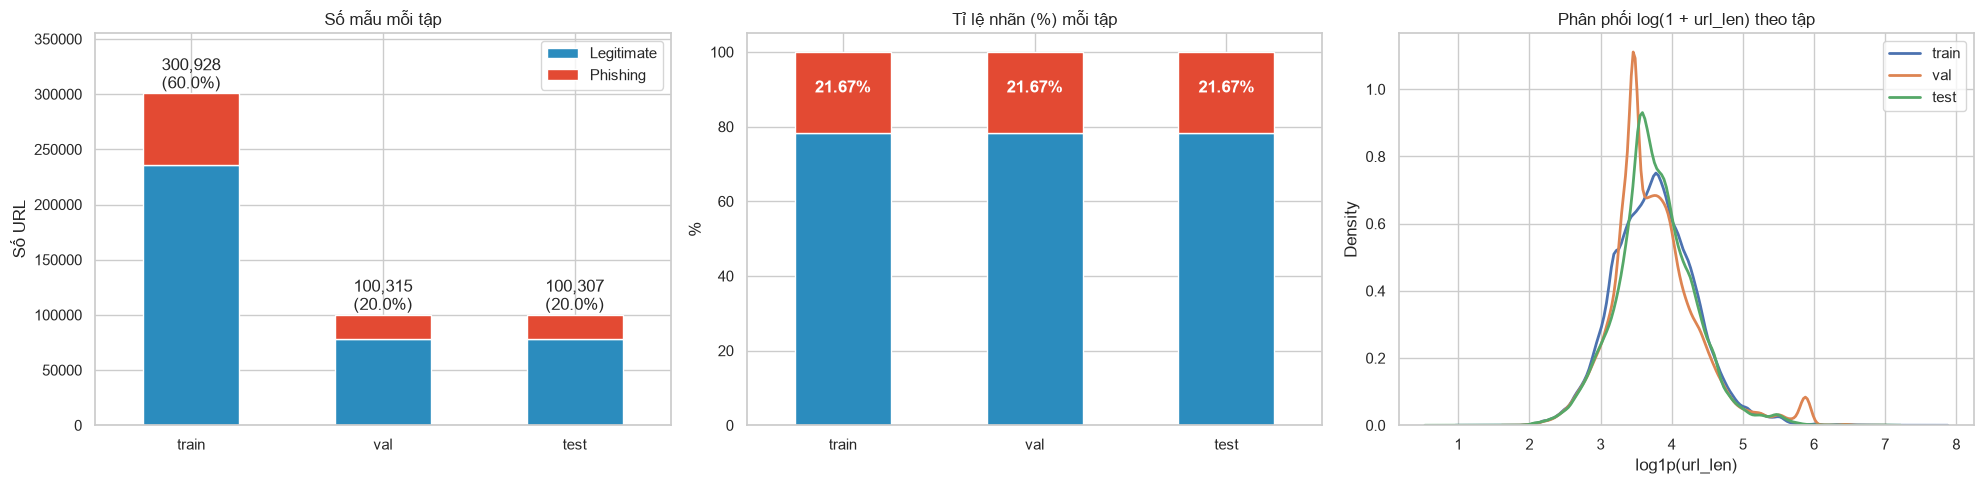

In [5]:
split_stats = pd.DataFrame({
    k: {'Số URL': len(v), 'Tỉ lệ (%)': len(v) / len(df) * 100, 'Số domain': len(dom_sets[k]),
        'Legitimate': int((y_all[v] == 0).sum()), 'Phishing': int((y_all[v] == 1).sum()),
        '% Phishing': y_all[v].mean() * 100}
    for k, v in split_idx.items()}).T.loc[SPLITS]
contingency = split_stats[['Legitimate', 'Phishing']].to_numpy(dtype=float)
chi2_stat, p_homo, dof, _ = stats.chi2_contingency(contingency)
cramers_v = np.sqrt(chi2_stat / (contingency.sum() * (min(contingency.shape) - 1)))
display(split_stats.style.format({'Số URL': '{:,.0f}', 'Tỉ lệ (%)': '{:.2f}', 'Số domain': '{:,.0f}',
                                  'Legitimate': '{:,.0f}', 'Phishing': '{:,.0f}', '% Phishing': '{:.3f}'}))
print(f'Kiểm định χ² đồng nhất tỉ lệ nhãn giữa 3 tập: χ² = {chi2_stat:.3f}, df = {dof}, p = {p_homo:.3f}, '
      f"Cramér's V = {cramers_v:.5f}")
print('→ Không có khác biệt có ý nghĩa: tỉ lệ nhãn đồng đều giữa các tập.' if p_homo > 0.05 else
      '→ Có khác biệt về mặt thống kê, nhưng Cramér V ≈ 0 cho thấy khác biệt không đáng kể về độ lớn.')

# Tính đại diện: phân phối độ dài URL của val/test có giống train không?
len_by_split = {k: df.loc[v, 'url_norm'].str.len().to_numpy() for k, v in split_idx.items()}
for k in ['val', 'test']:
    ks = stats.ks_2samp(len_by_split['train'], len_by_split[k])
    print(f'KS(url_len): train vs {k}: D = {ks.statistic:.4f}')
split_stats.to_csv(REPORT_DIR / 'phase2_split_stats.csv')

fig, axes = plt.subplots(1, 3, figsize=(20, 5))
split_stats[['Legitimate', 'Phishing']].plot(kind='bar', stacked=True, ax=axes[0],
                                             color=[PALETTE['Legitimate'], PALETTE['Phishing']], rot=0)
for i, (n, pct) in enumerate(zip(split_stats['Số URL'], split_stats['Tỉ lệ (%)'])):
    axes[0].text(i, n, f'{n:,.0f}\n({pct:.1f}%)', ha='center', va='bottom')
axes[0].set(title='Số mẫu mỗi tập', ylabel='Số URL', ylim=(0, split_stats['Số URL'].max() * 1.18))
(split_stats[['Legitimate', 'Phishing']].div(split_stats['Số URL'], axis=0) * 100).plot(
    kind='bar', stacked=True, ax=axes[1], color=[PALETTE['Legitimate'], PALETTE['Phishing']], rot=0, legend=False)
for i, pct in enumerate(split_stats['% Phishing']):
    axes[1].text(i, 100 - pct / 2, f'{pct:.2f}%', ha='center', color='white', fontweight='bold')
axes[1].set(title='Tỉ lệ nhãn (%) mỗi tập', ylabel='%')
for k in SPLITS:
    sns.kdeplot(np.log1p(len_by_split[k]), ax=axes[2], label=k, lw=2)
axes[2].set(title='Phân phối log(1 + url_len) theo tập', xlabel='log1p(url_len)')
axes[2].legend()
plt.tight_layout()
plt.show()

**Nhận xét: chất lượng phép chia**

- **Rò rỉ của cách chia cũ được định lượng:** nếu chia ngẫu nhiên, **76.1%** URL test có domain đã xuất hiện trong train. Kết quả của notebook 05 vì vậy đã bị đánh giá lạc quan.
- **Tỉ lệ đúng 60 / 20 / 20:** 300,928 (60.00%) / 100,315 (20.00%) / 100,307 (20.00%) URL, tương ứng 90,938 / 30,274 / 30,323 domain **không giao nhau**.
- **Phân bố nhãn đồng đều tuyệt đối:** % phishing là 21.669% / 21.671% / 21.668%. Kiểm định χ² cho p = 1.000 và Cramér's V = 0.00002, tức không có bất kỳ khác biệt nào giữa các tập.
- **Tính đại diện:** KS D của `url_len` giữa train và val/test chỉ là 0.061 / 0.045, và ba đường KDE gần như trùng nhau. Val/Test phản ánh đúng phân phối của Train, nhưng vẫn là **domain mới**. Đây chính là kịch bản zero-day mà hệ thống cần đối mặt.

## 4. Trích xuất đặc trưng số (đầu vào cho bước làm sạch)

Để xử lý lệch và ngoại lai ta cần các **biến số**. Hàm `build_feature_frame` trong `src/phishing_ml/features.py` (kế thừa notebook 06) sinh **60 đặc trưng số + 1 biến phân loại `tld`** từ URL. Phase 3 sẽ phân tích ý nghĩa bảo mật và chọn lọc chúng. Ở đây ta chỉ quan tâm đến **tính chất thống kê** của chúng.

Hàm này là hàm **thuần túy theo từng dòng** (row-wise, không học tham số từ dữ liệu), nên có thể chạy trên toàn bộ dữ liệu mà không gây rò rỉ.

In [6]:
t0 = time.time()
F = build_feature_frame(df['url'])
print(f'Trích xuất {F.shape[1]} cột cho {len(F):,} URL trong {time.time() - t0:.1f}s')

F_tr = F.iloc[split_idx['train']]
NUM_COLS = [c for c in F.columns if c != 'tld' and F_tr[c].nunique() > 1]
CONST_COLS = [c for c in F.columns if c != 'tld' and c not in NUM_COLS]
BINARY_COLS = [c for c in NUM_COLS if set(np.unique(F_tr[c])) <= {0, 1}]
CONT_COLS = [c for c in NUM_COLS if c not in BINARY_COLS]
train_skew = F_tr[CONT_COLS].skew()
SKEWED_COLS = train_skew.index[train_skew.abs() > 1].tolist()      # lệch mạnh → clip + Yeo-Johnson
MILD_COLS = [c for c in CONT_COLS if c not in SKEWED_COLS]           # lệch nhẹ → clip + RobustScaler

col_groups = pd.DataFrame({
    'Nhóm xử lý': ['Liên tục, lệch mạnh (|skew| > 1)', 'Liên tục, lệch nhẹ', 'Nhị phân (cờ 0/1)',
                   'Phân loại', 'Hằng số trên Train (loại)'],
    'Số cột': [len(SKEWED_COLS), len(MILD_COLS), len(BINARY_COLS), 1, len(CONST_COLS)],
    'Phép biến đổi': ['IQRClipper → Yeo-Johnson (+ chuẩn hóa z-score)', 'IQRClipper → RobustScaler',
                      'Giữ nguyên (passthrough)', 'TargetEncoder (cross-fit 5 fold) → StandardScaler', '—'],
    'Các cột': [', '.join(SKEWED_COLS), ', '.join(MILD_COLS), ', '.join(BINARY_COLS), 'tld', ', '.join(CONST_COLS)],
})
display(col_groups)

Trích xuất 61 cột cho 501,550 URL trong 34.3s


,Nhóm xử lý,Số cột,Phép biến đổi,Các cột
0,"Liên tục, lệch mạnh (|skew| > 1)",35,IQRClipper → Yeo-Johnson (+ chuẩn hóa z-score),"url_len, path_len, query_len, path_depth, n_pa..."
1,"Liên tục, lệch nhẹ",4,IQRClipper → RobustScaler,"special_ratio, url_entropy, host_entropy, sld_..."
2,Nhị phân (cờ 0/1),21,Giữ nguyên (passthrough),"has_port, has_userinfo, double_slash_in_path, ..."
3,Phân loại,1,TargetEncoder (cross-fit 5 fold) → StandardScaler,tld
4,Hằng số trên Train (loại),0,—,


## 5. Phân phối lệch (Skewness) và Ngoại lai (Outliers)

### 5.1. Chẩn đoán trên tập Train
Hai quy tắc ngoại lai được báo cáo song song: **Tukey 1.5·IQR** (ngoại lai thường) và **3·IQR** ("far-out", ngoại lai cực trị).

In [7]:
def outlier_stats(frame: pd.DataFrame) -> pd.DataFrame:
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return pd.DataFrame({
        'Skewness': frame.skew(), 'Kurtosis': frame.kurt(), 'IQR': iqr,
        '% ngoại lai 1.5·IQR': ((frame < q1 - 1.5 * iqr) | (frame > q3 + 1.5 * iqr)).mean() * 100,
        '% ngoại lai 3·IQR': ((frame < q1 - 3 * iqr) | (frame > q3 + 3 * iqr)).mean() * 100,
        'Max': frame.max(), 'P99': frame.quantile(0.99),
    })


before_stats = outlier_stats(F_tr[CONT_COLS]).sort_values('Skewness', key=np.abs, ascending=False)
display(before_stats.style.format('{:,.3f}').background_gradient(subset=['Skewness', '% ngoại lai 3·IQR'],
                                                                  cmap='Reds'))

,Skewness,Kurtosis,IQR,% ngoại lai 1.5·IQR,% ngoại lai 3·IQR,Max,P99
n_percent,37.172,"1,995.879",0.000,2.297,2.297,126.000,2.000
longest_token,27.050,"2,620.450",5.000,6.714,4.212,"2,245.000",64.000
n_at,21.246,708.301,0.000,0.335,0.335,6.000,0.000
n_underscores,21.237,"2,639.520",0.000,16.426,16.426,200.000,5.000
sens_in_host,16.901,415.490,0.000,1.019,1.019,12.000,1.000
host_n_digits,16.407,339.513,0.000,7.605,7.605,113.000,10.000
query_len,15.574,453.460,0.000,13.980,13.980,"2,245.000",122.000
avg_token_len,14.600,"1,375.375",1.893,5.289,1.583,328.714,13.500
subdomain_len,10.195,137.303,2.000,18.816,11.598,226.000,28.000
host_n_hyphens,9.539,148.174,0.000,7.163,7.163,14.000,2.000


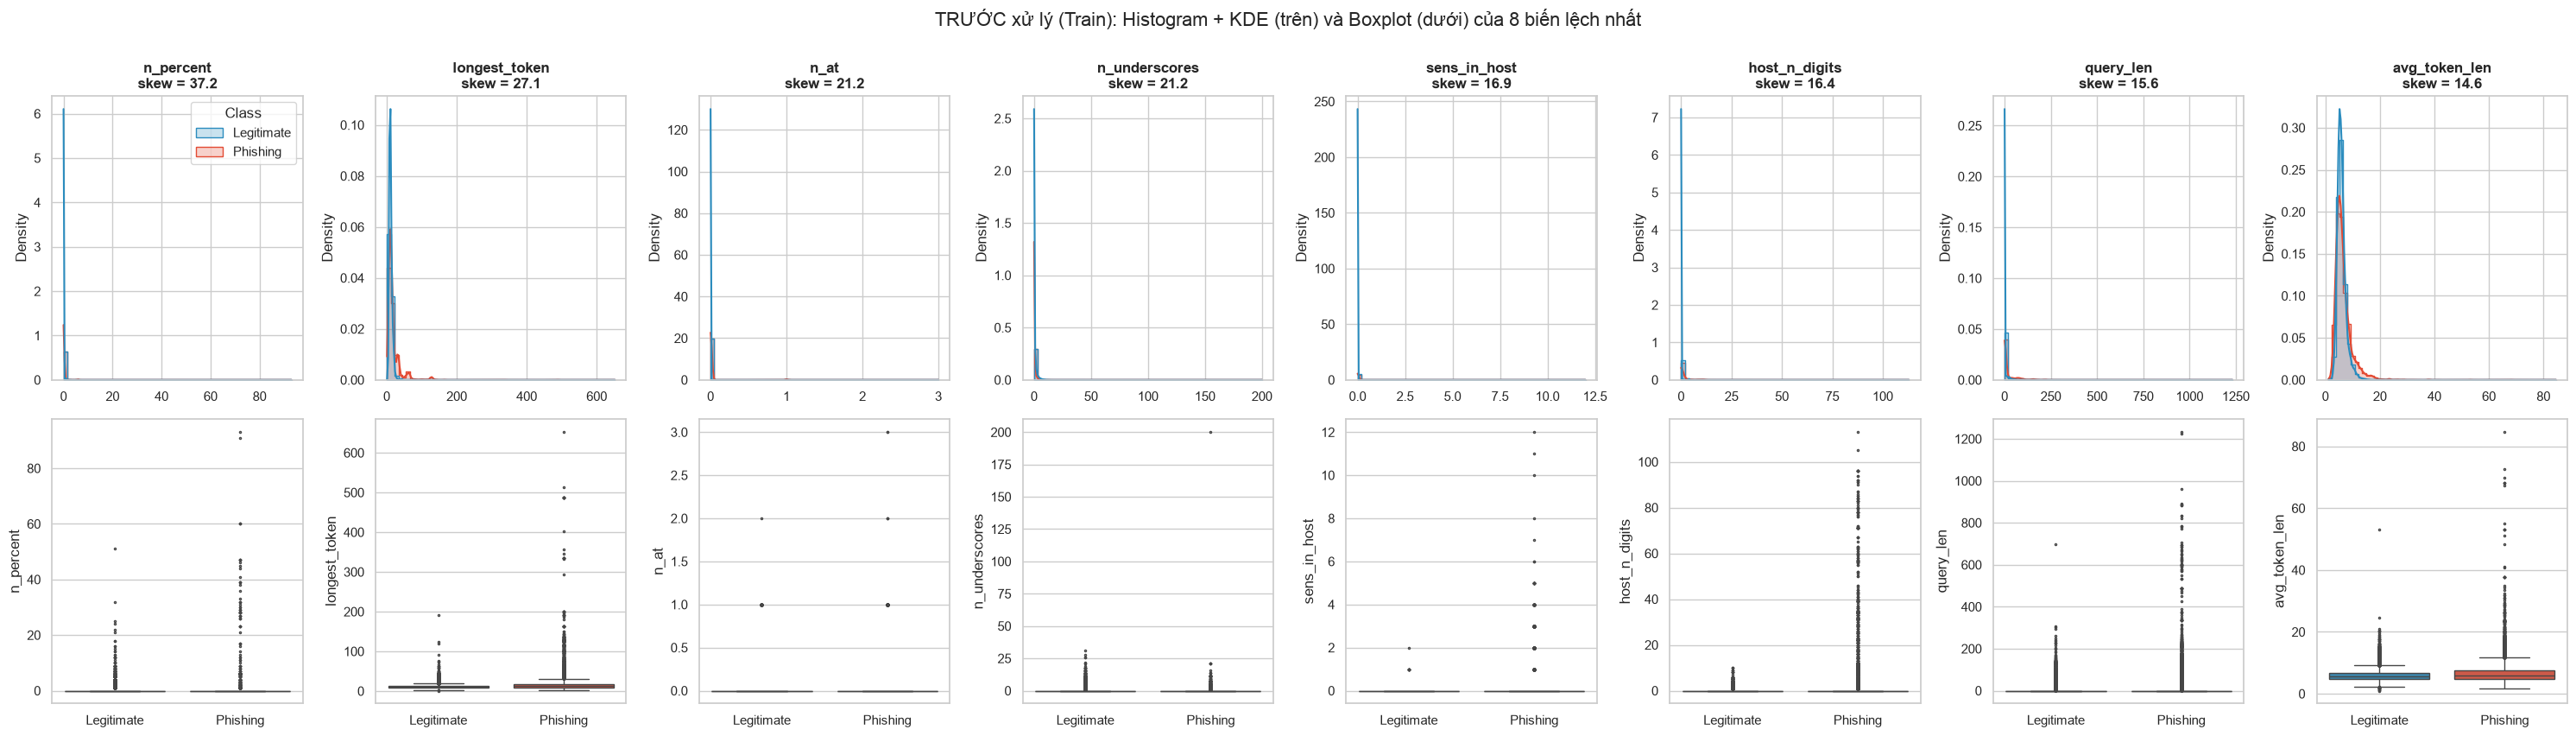

In [8]:
SHOW = before_stats.index[:8].tolist()
y_tr = y_all[split_idx['train']]
viz = F_tr[SHOW].assign(Class=np.where(y_tr == 1, 'Phishing', 'Legitimate')).sample(80_000,
                                                                                      random_state=RANDOM_STATE)
fig, axes = plt.subplots(2, 8, figsize=(30, 8.5))
for j, col in enumerate(SHOW):
    sns.histplot(data=viz, x=col, hue='Class', stat='density', common_norm=False, bins=60, kde=True,
                 element='step', palette=PALETTE, ax=axes[0, j], legend=(j == 0))
    axes[0, j].set_title(f'{col}\nskew = {before_stats.loc[col, "Skewness"]:.1f}', fontweight='bold')
    axes[0, j].set_xlabel('')
    sns.boxplot(data=viz, x='Class', y=col, hue='Class', palette=PALETTE, fliersize=1.5, legend=False, ax=axes[1, j])
    axes[1, j].set_xlabel('')
fig.suptitle('TRƯỚC xử lý (Train): Histogram + KDE (trên) và Boxplot (dưới) của 8 biến lệch nhất', fontsize=16, y=1.0)
plt.tight_layout()
plt.show()

**Nhận xét: chẩn đoán trước xử lý**

- **35/39 biến liên tục lệch mạnh** (|skew| > 1). Trung vị |skew| là 6.6, trung vị kurtosis là 71. Nặng nhất là `n_percent` (skew 37, kurtosis ≈ 2,000), `longest_token` (27) và `n_at`, `n_underscores` (≈ 21).
- **Histogram:** khối lượng dồn về sát 0, còn đuôi phải kéo dài tới hàng trăm hoặc hàng nghìn. Lớp **Phishing chiếm ưu thế ở đuôi** (đường đỏ nằm trên đường xanh ở vùng giá trị lớn).
- **Boxplot:** "râu" của lớp Legitimate rất ngắn, còn các điểm ngoại lai dày đặc **chủ yếu thuộc lớp Phishing**. Điều này khẳng định lại quyết định chỉ **cắt mềm** (Winsorizing), không xóa dòng.

### 5.2. Chọn phép biến đổi giảm lệch: log1p vs Box-Cox vs Yeo-Johnson

So sánh |skewness| sau biến đổi trên Train. **Box-Cox** chỉ áp dụng được cho giá trị > 0, nên ta dùng x + 1. **Yeo-Johnson** chấp nhận giá trị 0 hoặc âm và học λ tối ưu theo MLE.

In [9]:
samp = F_tr[SKEWED_COLS].sample(100_000, random_state=RANDOM_STATE).astype(float)
cmp_rows = []
for c in SKEWED_COLS:
    x = samp[c].to_numpy()
    row = {'Biến': c, 'Gốc': stats.skew(x), 'log1p': stats.skew(np.log1p(x))}
    try:
        row['Box-Cox (x+1)'] = stats.skew(stats.boxcox(x + 1)[0])
    except ValueError:
        row['Box-Cox (x+1)'] = np.nan
    row['Yeo-Johnson'] = stats.skew(stats.yeojohnson(x)[0])
    cmp_rows.append(row)
transform_cmp = pd.DataFrame(cmp_rows).set_index('Biến')
abs_cmp = transform_cmp.abs()
display(abs_cmp.style.format('{:.3f}').highlight_min(axis=1, color='#c7e9c0'))
wins = abs_cmp.drop(columns='Gốc').idxmin(axis=1).value_counts()
print('Số biến mà mỗi phép biến đổi cho |skew| nhỏ nhất:', wins.to_dict())
print('Trung vị |skew|:', abs_cmp.median().round(3).to_dict())

,Gốc,log1p,Box-Cox (x+1),Yeo-Johnson
Biến,,,,
url_len,6.376,0.345,0.010,0.010
path_len,1.965,1.176,0.058,0.058
query_len,13.935,2.466,2.079,2.079
path_depth,1.302,0.340,0.009,0.009
n_params,7.082,3.024,2.078,2.078
n_dots,4.816,1.318,0.128,0.128
n_hyphens,3.424,1.327,0.602,0.602
n_underscores,41.038,2.768,1.818,1.818
n_slashes,1.415,0.299,0.005,0.005


Số biến mà mỗi phép biến đổi cho |skew| nhỏ nhất: {'Yeo-Johnson': 21, 'Box-Cox (x+1)': 14}
Trung vị |skew|: {'Gốc': 6.476, 'log1p': 2.347, 'Box-Cox (x+1)': 0.695, 'Yeo-Johnson': 0.695}


**Kết quả:** trung vị |skew| giảm từ **6.48 (gốc)** xuống **2.35 (log1p)** và **0.695 (Box-Cox / Yeo-Johnson)**. Yeo-Johnson thắng ở 21/35 biến, Box-Cox thắng ở 14 biến với chênh lệch không đáng kể.

**Quyết định (5-Whys):**
- *Vì sao không dùng log1p?* log1p có λ cố định, nên **chưa đủ mạnh** cho các biến đếm cực lệch (trung vị |skew| còn 2.35) và lại **quá mạnh** cho biến lệch vừa.
- *Vì sao không dùng Box-Cox?* Box-Cox đòi hỏi x > 0, nên phải dịch x + 1 một cách tùy ý, và không xử lý được dữ liệu âm sau này.
- **Yeo-Johnson** học λ riêng cho từng biến theo MLE trên Train, chấp nhận giá trị 0 và trong bảng trên nó cho |skew| thấp nhất ở đa số biến. Trong `sklearn.PowerTransformer`, λ được **lưu lại** sau `fit(train)` và dùng nguyên cho val/test, nên không có rò rỉ.
- **Thứ tự Clip → Yeo-Johnson:** cắt ngoại lai cực trị trước giúp ước lượng λ ổn định hơn, vì MLE của λ rất nhạy với vài giá trị khổng lồ (ví dụ `query_len` lên tới hàng nghìn).

### 5.3. Xử lý ngoại lai bằng Winsorizing (IQRClipper)

**Vì sao chỉ cắt (clip) mà không xóa dòng?** Ngoại lai ở đây phần lớn là **phishing thật**, ví dụ URL nhồi tham số hay subdomain giả dài. Xóa chúng là xóa chính tín hiệu cần học. Winsorizing đưa giá trị cực trị về biên, nên **giữ dòng và giữ thứ tự tương đối**.

`IQRClipper` (trong `src/phishing_ml/preprocessing.py`) dùng hàng rào **Tukey far-out [Q1 − 3·IQR, Q3 + 3·IQR]** với hai chốt an toàn:
1. Không bao giờ cắt quá **1% mỗi đuôi**, để tránh nghiền nát biến có phân phối hẹp nhưng đuôi dày.
2. Nếu IQR = 0 (biến đếm mà đa số bằng 0) thì dùng phân vị 0.1%/99.9%. Nếu không làm vậy, mọi giá trị khác 0 sẽ bị cắt về 0 và **cột trở thành hằng số**.

> ⚠️ **Hai nhánh dữ liệu:** Winsorizing và Yeo-Johnson chỉ phục vụ các mô hình **nhạy thang đo** (Logistic Regression, SVM, MLP). Các **mô hình cây** (RF, XGBoost, LightGBM, CatBoost) bất biến với biến đổi đơn điệu và tự xử lý ngoại lai, nên dùng **giá trị gốc**. Clip sẽ chỉ làm chúng mất thông tin ở đuôi phân phối, mà đuôi chính là nơi phishing tập trung (§5.1).

In [10]:
def make_preprocessor() -> ColumnTransformer:
    return ColumnTransformer([
        ('skewed', Pipeline([('clip', IQRClipper(k=3.0, max_tail=0.01)),
                             ('yeojohnson', PowerTransformer(method='yeo-johnson', standardize=True))]), SKEWED_COLS),
        ('mild', Pipeline([('clip', IQRClipper(k=3.0, max_tail=0.01)), ('robust', RobustScaler())]), MILD_COLS),
        ('binary', 'passthrough', BINARY_COLS),
        ('tld', Pipeline([('target_enc', TargetEncoder(target_type='binary', cv=5, shuffle=True,
                                                      random_state=RANDOM_STATE)),
                          ('scale', StandardScaler())]), ['tld']),
    ], verbose_feature_names_out=False).set_output(transform='pandas')


X_raw = {k: F.iloc[v].reset_index(drop=True) for k, v in split_idx.items()}
y = {k: y_all[v] for k, v in split_idx.items()}

t0 = time.time()
preprocessor = make_preprocessor()
X_scaled = {'train': preprocessor.fit_transform(X_raw['train'][NUM_COLS + ['tld']], y['train'])}   # FIT chỉ trên train
for k in ['val', 'test']:
    X_scaled[k] = preprocessor.transform(X_raw[k][NUM_COLS + ['tld']])                         # chỉ TRANSFORM
X_scaled = {k: v.rename(columns={'tld': 'tld_te'}).astype(np.float32) for k, v in X_scaled.items()}
SCALED_COLS = list(X_scaled['train'].columns)
print(f'Preprocessor fit + transform: {time.time() - t0:.1f}s | Ma trận: ' +
      ', '.join(f'{k} {v.shape}' for k, v in X_scaled.items()))

# Báo cáo tham số đã học (CHỈ từ train)
clip_sk = preprocessor.named_transformers_['skewed'].named_steps['clip']
clip_md = preprocessor.named_transformers_['mild'].named_steps['clip']
yj = preprocessor.named_transformers_['skewed'].named_steps['yeojohnson']
learned = pd.concat([
    pd.DataFrame({'Biên dưới': clip_sk.lower_, 'Biên trên': clip_sk.upper_, 'λ Yeo-Johnson': yj.lambdas_,
                  '% bị cắt (train)': clip_sk.clipped_fraction(X_raw['train'][SKEWED_COLS]) * 100,
                  '% bị cắt (test)': clip_sk.clipped_fraction(X_raw['test'][SKEWED_COLS]) * 100}, index=SKEWED_COLS),
    pd.DataFrame({'Biên dưới': clip_md.lower_, 'Biên trên': clip_md.upper_, 'λ Yeo-Johnson': np.nan,
                  '% bị cắt (train)': clip_md.clipped_fraction(X_raw['train'][MILD_COLS]) * 100,
                  '% bị cắt (test)': clip_md.clipped_fraction(X_raw['test'][MILD_COLS]) * 100}, index=MILD_COLS)])
display(learned.style.format('{:,.3f}', na_rep='—'))

Preprocessor fit + transform: 18.3s | Ma trận: train (300928, 61), val (100315, 61), test (100307, 61)


,Biên dưới,Biên trên,λ Yeo-Johnson,% bị cắt (train),% bị cắt (test)
url_len,-71.000,200.000,-0.114,0.998,1.107
path_len,-67.000,115.000,0.405,0.833,0.914
query_len,0.000,122.000,-2.135,0.993,0.943
path_depth,-5.000,9.000,0.275,0.208,0.282
n_params,0.000,4.000,-7.460,0.786,0.708
n_dots,-2.000,8.000,-1.155,0.824,0.840
n_hyphens,-3.000,12.000,-1.372,0.860,0.723
n_underscores,0.000,5.000,-5.876,0.988,1.348
n_slashes,-5.000,9.000,0.237,0.298,0.332
n_at,0.000,1.000,-110.420,0.006,0.011


### 5.4. Target Encoding cho biến phân loại `tld`

Có hơn 800 TLD. One-hot sẽ tạo ma trận rất thưa và không chia sẻ thông tin giữa các TLD hiếm. **Target Encoding** thay mỗi TLD bằng **tỉ lệ phishing đã làm mượt** (smoothing theo cỡ mẫu). `TargetEncoder.fit_transform` của scikit-learn dùng **cross-fitting 5 fold** trên Train: mỗi dòng train được mã hóa bằng thống kê tính từ 4 fold **không chứa nó**. Nhờ vậy giá trị mã hóa không "nhìn thấy" nhãn của chính dòng đó, tránh target leakage. Val/Test dùng thống kê học từ **toàn bộ** Train.

In [11]:
te = preprocessor.named_transformers_['tld'].named_steps['target_enc']
tld_map = (pd.DataFrame({'tld': te.categories_[0], 'Giá trị mã hóa': te.encodings_[0]})
           .merge(X_raw['train']['tld'].value_counts().rename('Số URL train'), left_on='tld', right_index=True)
           .query('`Số URL train` >= 300').sort_values('Giá trị mã hóa', ascending=False))
print(f'{len(te.categories_[0])} TLD đã học | tỉ lệ phishing nền (train) = {y["train"].mean():.4f}')
display(pd.concat([tld_map.head(8), tld_map.tail(5)]).set_index('tld'))
unseen = (~X_raw['test']['tld'].isin(te.categories_[0])).mean()
print(f'TLD trong test chưa từng thấy ở train: {unseen:.3%} → được gán giá trị trung bình toàn cục')

668 TLD đã học | tỉ lệ phishing nền (train) = 0.2167


,Giá trị mã hóa,Số URL train
tld,,
mx,0.9941,688
<ip>,0.9935,2146
cn,0.9847,591
asia,0.9846,524
com.br,0.9776,1877
cl,0.9764,597
tk,0.9755,534
ly,0.9555,386
gc.ca,0.0033,305


TLD trong test chưa từng thấy ở train: 0.173% → được gán giá trị trung bình toàn cục


## 6. Mất cân bằng lớp (Class Imbalance)

### 6.1. Mức độ mất cân bằng và thực nghiệm so sánh chiến lược

Ta so sánh ba chiến lược **trên Train, đánh giá trên Validation**, dùng một Logistic Regression trên đặc trưng đã chuẩn hóa:
1. **Không xử lý.**
2. **Class weights** (`class_weight='balanced'`): phạt lỗi trên lớp thiểu số nặng hơn theo tỉ lệ nghịch tần suất.
3. **Random Oversampling** lớp thiểu số trên Train cho tới khi cân bằng.

SMOTE **không** được thử: nội suy giữa hai URL sinh ra các vector "ảo" (ví dụ 2.7 dấu chấm, `host_is_ip` = 0.4) không tương ứng với URL nào có thật, và không áp dụng được cho TF-IDF.

In [12]:
n0, n1 = int((y['train'] == 0).sum()), int((y['train'] == 1).sum())
CLASS_WEIGHTS = {0: len(y['train']) / (2 * n0), 1: len(y['train']) / (2 * n1)}
SCALE_POS_WEIGHT = n0 / n1
print(f'Train: {n0:,} hợp lệ vs {n1:,} phishing → tỉ lệ {SCALE_POS_WEIGHT:.3f} : 1')
print(f'Class weights = {{0: {CLASS_WEIGHTS[0]:.4f}, 1: {CLASS_WEIGHTS[1]:.4f}}} | scale_pos_weight = {SCALE_POS_WEIGHT:.4f}')

rng = np.random.default_rng(RANDOM_STATE)
pos = np.where(y['train'] == 1)[0]
over_idx = np.concatenate([np.arange(len(y['train'])), rng.choice(pos, n0 - n1, replace=True)])
strategies = {
    'Không xử lý': (X_scaled['train'], y['train'], None),
    "class_weight='balanced'": (X_scaled['train'], y['train'], 'balanced'),
    'Random Oversampling': (X_scaled['train'].iloc[over_idx], y['train'][over_idx], None),
}
imb_rows = []
for name, (Xt, yt, cw) in strategies.items():
    t0 = time.time()
    m = LogisticRegression(max_iter=2000, class_weight=cw).fit(Xt, yt)
    p = m.predict_proba(X_scaled['val'])[:, 1]
    pred = (p >= 0.5).astype(int)
    imb_rows.append({'Chiến lược': name, 'Số mẫu train': len(yt), 'PR-AUC (val)': average_precision_score(y['val'], p),
                     'Precision@0.5': precision_score(y['val'], pred), 'Recall@0.5': recall_score(y['val'], pred),
                     'F1@0.5': f1_score(y['val'], pred), 'Thời gian (s)': time.time() - t0})
imbalance_exp = pd.DataFrame(imb_rows).set_index('Chiến lược')
display(imbalance_exp)

Train: 235,721 hợp lệ vs 65,207 phishing → tỉ lệ 3.615 : 1
Class weights = {0: 0.6383, 1: 2.3075} | scale_pos_weight = 3.6150


,Số mẫu train,PR-AUC (val),Precision@0.5,Recall@0.5,F1@0.5,Thời gian (s)
Chiến lược,,,,,,
Không xử lý,300928,0.8846,0.9005,0.7078,0.7926,1.6684
class_weight='balanced',300928,0.8822,0.7299,0.8248,0.7745,1.7273
Random Oversampling,471442,0.8821,0.7302,0.8241,0.7743,2.7203


**Nhận xét: mất cân bằng ảnh hưởng tới *ngưỡng*, không ảnh hưởng tới *xếp hạng***

- Ba chiến lược cho **PR-AUC gần như bằng nhau** (0.885 / 0.882 / 0.882), tức khả năng *xếp hạng* rủi ro không đổi. Khác biệt chỉ nằm ở **điểm vận hành tại ngưỡng 0.5**: không xử lý cho Precision 0.90 / Recall 0.71, còn có trọng số cho Precision 0.73 / Recall 0.82.
- **Class weights và Random Oversampling cho kết quả gần như đồng nhất** (Recall 0.825 so với 0.824), nhưng oversampling cần nhiều hơn **57% dữ liệu** (471k so với 301k dòng) và lặp lại mẫu, nên dễ overfit với mô hình cây sâu.
- **Quyết định:** dùng **class weights** (`class_weight='balanced'`, `scale_pos_weight` = 3.615) cho mọi mô hình ở Phase 4, kết hợp **chọn ngưỡng tối ưu trên Validation**. Đây là cách kiểm soát đánh đổi Precision/Recall trực tiếp nhất, không tạo dữ liệu nhân tạo và không làm thay đổi phân phối của tập Train.

## 7. Biểu diễn chuỗi: TF-IDF char n-gram + token

Đặc trưng thủ công làm mất thông tin chuỗi. Phase 1 cho thấy nhiều URL khác nhãn nhưng trùng vector mô tả. **TF-IDF** khôi phục thông tin này:
- **Char n-gram (3–5)** trên URL chuẩn hóa bắt được mảnh như `ogin`, `.php?`, `aypa`, `webscr`, kể cả khi bị viết sai hoặc ghép dính.
- **Token** (chuỗi chữ-số ≥ 2 ký tự) bắt được các từ nguyên vẹn như `paypal`, `wp`, `includes`.
- `sublinear_tf=True` dùng 1 + log(tf), nên giảm ảnh hưởng của n-gram lặp nhiều lần. Đây chính là "xử lý lệch" cho biến đếm n-gram.

Vocabulary và trọng số IDF được học **chỉ trên Train**. N-gram chỉ có ở val/test bị bỏ qua (OOV), đúng như những gì xảy ra khi triển khai thật.

In [13]:
texts = {k: df.loc[v, 'url_norm'].tolist() for k, v in split_idx.items()}
char_vec = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=5, max_features=300_000,
                           sublinear_tf=True, dtype=np.float32)
word_vec = TfidfVectorizer(token_pattern=r'[a-z0-9]{2,}', min_df=3, sublinear_tf=True, dtype=np.float32)

t0 = time.time()
T = {'train': sparse.hstack([char_vec.fit_transform(texts['train']),
                             word_vec.fit_transform(texts['train'])]).tocsr()}
for k in ['val', 'test']:
    T[k] = sparse.hstack([char_vec.transform(texts[k]), word_vec.transform(texts[k])]).tocsr()
print(f'TF-IDF fit (train) + transform: {time.time() - t0:.1f}s')

tfidf_info = pd.DataFrame({k: {'Số hàng': m.shape[0], 'Số cột': m.shape[1], 'Số phần tử ≠ 0': m.nnz,
                               'Mật độ (%)': m.nnz / (m.shape[0] * m.shape[1]) * 100,
                               'nnz trung bình / URL': m.nnz / m.shape[0],
                               'URL có vector rỗng (%)': (m.getnnz(axis=1) == 0).mean() * 100}
                           for k, m in T.items()}).T
print(f'Vocabulary: char = {len(char_vec.vocabulary_):,} | token = {len(word_vec.vocabulary_):,}')
display(tfidf_info)
for v in (char_vec, word_vec):        # bỏ danh sách n-gram bị lọc (rất lớn, không cần cho inference)
    if hasattr(v, 'stop_words_'):
        delattr(v, 'stop_words_')

TF-IDF fit (train) + transform: 41.1s
Vocabulary: char = 300,000 | token = 45,923


,Số hàng,Số cột,Số phần tử ≠ 0,Mật độ (%),nnz trung bình / URL,URL có vector rỗng (%)
train,"300,928.0000","345,923.0000","37,685,581.0000",0.0362,125.2312,0.0037
val,"100,315.0000","345,923.0000","11,823,886.0000",0.0341,117.8676,0.0040
test,"100,307.0000","345,923.0000","11,912,873.0000",0.0343,118.7641,0.0060


## 8. Đối chiếu Trước vs. Sau xử lý

### 8.1. Bảng thống kê tổng hợp
Bảng so sánh **Train trước xử lý** (giá trị gốc), **Train sau xử lý** và **Val/Test sau xử lý** (dùng tham số học từ Train). Kỳ vọng:
- |Skewness| và Kurtosis giảm mạnh, % ngoại lai giảm về gần 0.
- Train sau xử lý có mean ≈ 0, std ≈ 1 (với nhóm Yeo-Johnson).
- Val/Test **gần** nhưng **không đúng bằng** 0/1. Đây là bằng chứng transformer **không** được fit lại trên chúng (không rò rỉ).

In [14]:
def summary_block(frame: pd.DataFrame, cols) -> pd.DataFrame:
    s = outlier_stats(frame[cols].astype(float))
    return pd.DataFrame({'Mean': frame[cols].mean(), 'Std': frame[cols].std(), 'Skewness': s['Skewness'],
                         'Kurtosis': s['Kurtosis'], '% ngoại lai 1.5·IQR': s['% ngoại lai 1.5·IQR']})


blocks = {'Train TRƯỚC': summary_block(X_raw['train'], CONT_COLS),
          'Train SAU': summary_block(X_scaled['train'], CONT_COLS),
          'Val SAU': summary_block(X_scaled['val'], CONT_COLS),
          'Test SAU': summary_block(X_scaled['test'], CONT_COLS)}
before_after = pd.concat(blocks, axis=1)
before_after.to_csv(REPORT_DIR / 'phase2_before_after.csv')
display(before_after.loc[SKEWED_COLS[:12]].style.format('{:,.3f}'))

agg = pd.DataFrame({name: {'Trung vị |Skewness|': b['Skewness'].abs().median(),
                           'Max |Skewness|': b['Skewness'].abs().max(),
                           'Trung vị Kurtosis': b['Kurtosis'].median(),
                           'Trung bình % ngoại lai (1.5·IQR)': b['% ngoại lai 1.5·IQR'].mean(),
                           'Max |Mean|': b['Mean'].abs().max(),
                           'Khoảng Std': f"{b['Std'].min():.2f} – {b['Std'].max():.2f}"}
                    for name, b in blocks.items()}).T
print('Tổng hợp trên toàn bộ', len(CONT_COLS), 'biến liên tục:')
display(agg)

Tổng hợp trên toàn bộ 39 biến liên tục:


,Trung vị |Skewness|,Max |Skewness|,Trung vị Kurtosis,Trung bình % ngoại lai (1.5·IQR),Max |Mean|,Khoảng Std
Train TRƯỚC,6.6266,37.1717,71.3460,6.4106,50.4351,0.04 – 40.88
Train SAU,0.5797,17.1915,0.6427,3.7285,0.0491,0.76 – 1.00
Val SAU,0.5899,16.7467,0.4027,5.8721,0.3139,0.20 – 1.25
Test SAU,0.7378,24.4743,1.1059,3.4404,0.3204,0.13 – 1.23


### 8.2. Trực quan hóa Trước vs. Sau

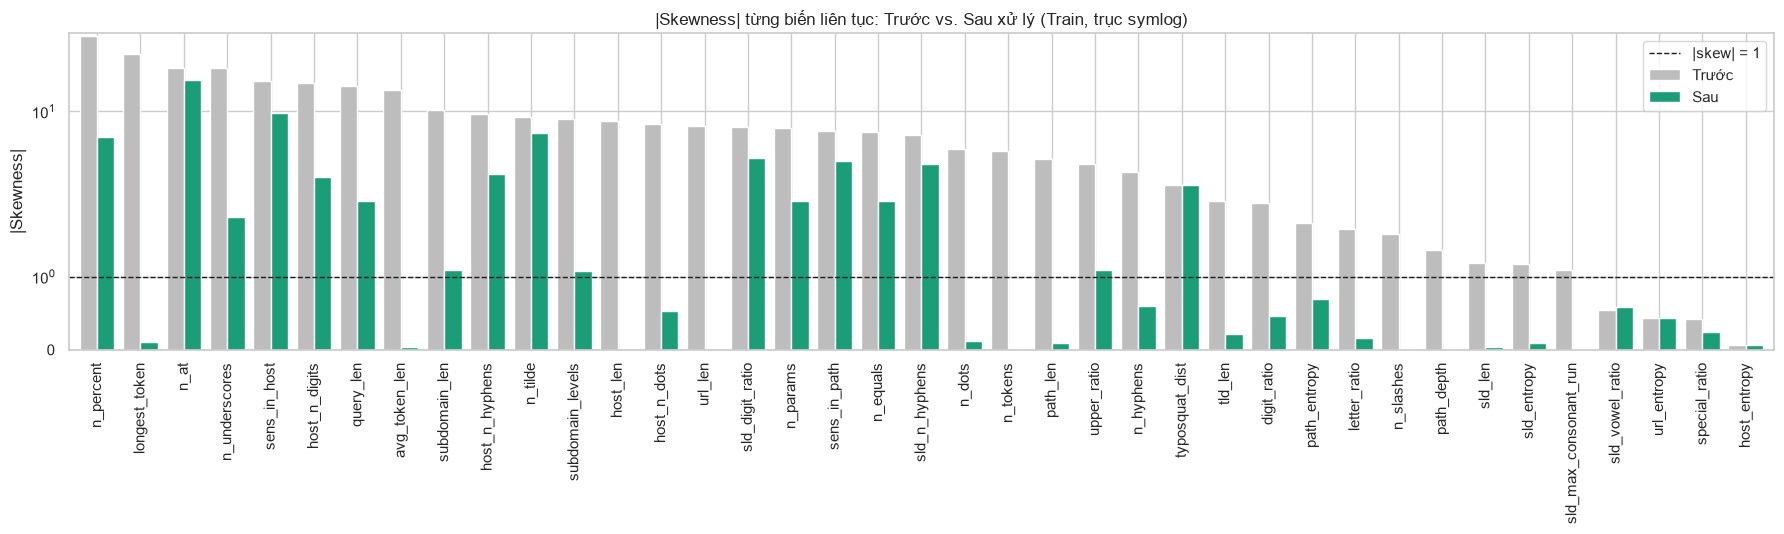

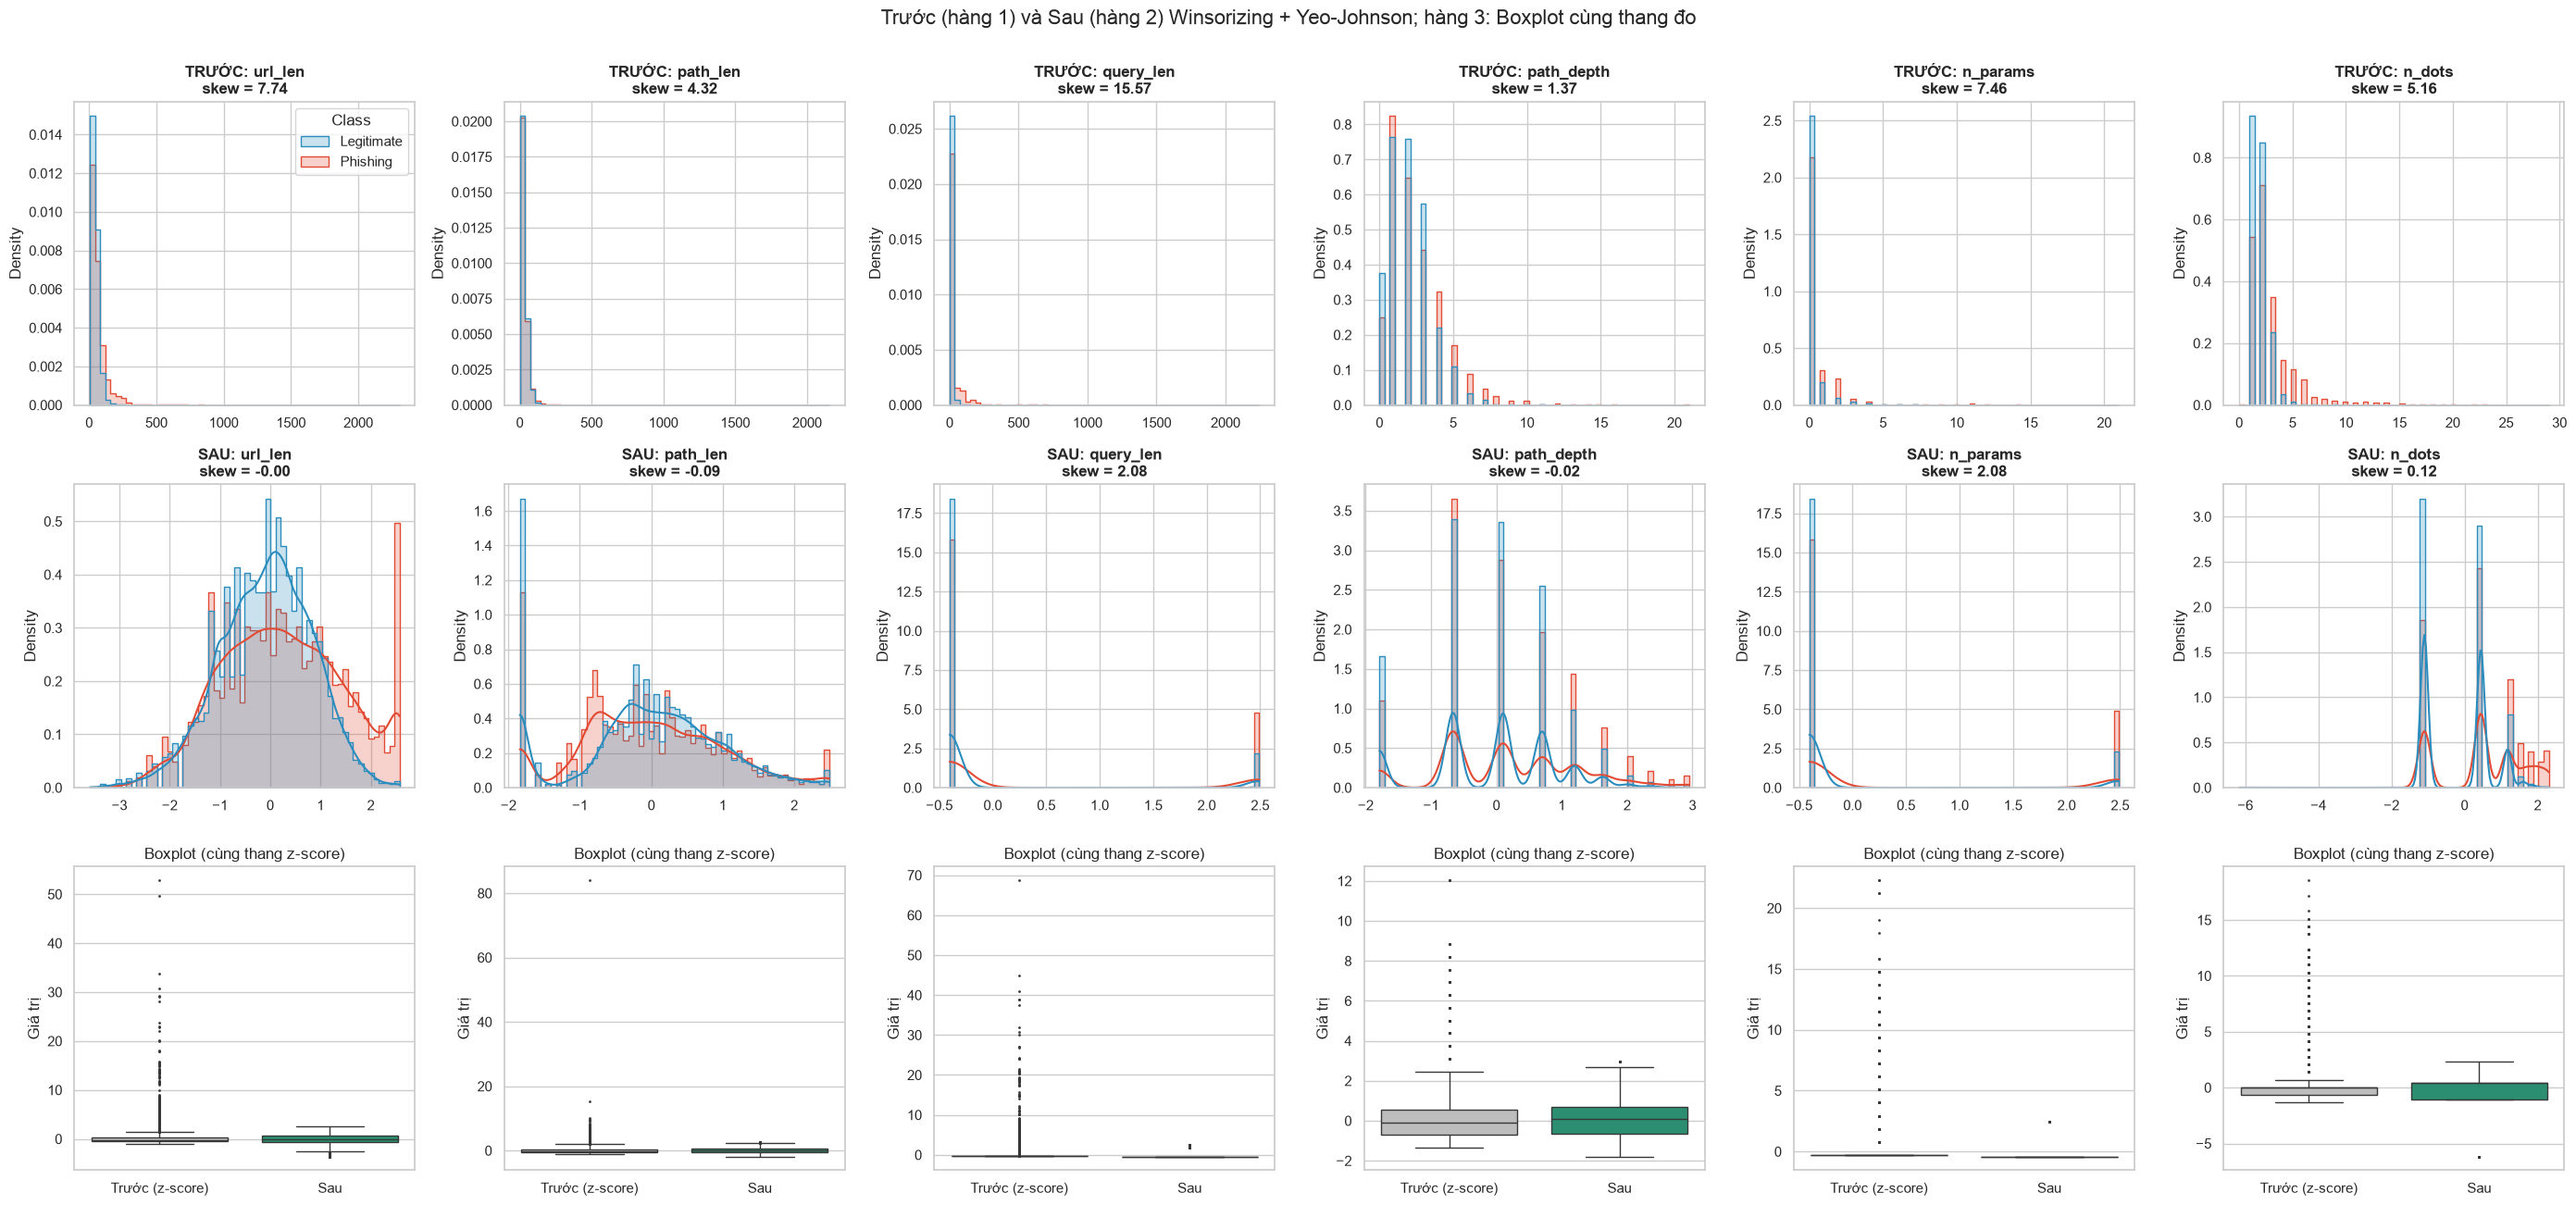

In [15]:
fig, ax = plt.subplots(figsize=(18, 5.5))
sk = pd.DataFrame({'Trước': blocks['Train TRƯỚC']['Skewness'].abs(),
                   'Sau': blocks['Train SAU']['Skewness'].abs()}).sort_values('Trước', ascending=False)
sk.plot(kind='bar', ax=ax, color=['#bdbdbd', '#1b9e77'], width=0.8)
ax.axhline(1, ls='--', c='k', lw=1, label='|skew| = 1')
ax.set_yscale('symlog')
ax.set(title='|Skewness| từng biến liên tục: Trước vs. Sau xử lý (Train, trục symlog)', ylabel='|Skewness|')
ax.legend()
plt.tight_layout()
plt.show()

COMPARE = SKEWED_COLS[:6]
cls_tr = np.where(y['train'] == 1, 'Phishing', 'Legitimate')
samp_i = np.random.default_rng(1).choice(len(y['train']), 60_000, replace=False)
fig, axes = plt.subplots(3, 6, figsize=(28, 13))
for j, col in enumerate(COMPARE):
    before = pd.DataFrame({col: X_raw['train'][col].to_numpy()[samp_i], 'Class': cls_tr[samp_i]})
    after = pd.DataFrame({col: X_scaled['train'][col].to_numpy()[samp_i], 'Class': cls_tr[samp_i]})
    sns.histplot(data=before, x=col, hue='Class', stat='density', common_norm=False, bins=60, element='step',
                 palette=PALETTE, ax=axes[0, j], legend=(j == 0))
    axes[0, j].set_title(f'TRƯỚC: {col}\nskew = {blocks["Train TRƯỚC"].loc[col, "Skewness"]:.2f}', fontweight='bold')
    sns.histplot(data=after, x=col, hue='Class', stat='density', common_norm=False, bins=60, element='step', kde=True,
                 palette=PALETTE, ax=axes[1, j], legend=False)
    axes[1, j].set_title(f'SAU: {col}\nskew = {blocks["Train SAU"].loc[col, "Skewness"]:.2f}', fontweight='bold')
    box = pd.DataFrame({'Giai đoạn': ['Trước (z-score)'] * len(samp_i) + ['Sau'] * len(samp_i),
                        'Giá trị': np.concatenate([stats.zscore(before[col]), after[col]])})
    sns.boxplot(data=box, x='Giai đoạn', y='Giá trị', hue='Giai đoạn', palette=['#bdbdbd', '#1b9e77'],
                fliersize=1, legend=False, ax=axes[2, j])
    axes[2, j].set_title('Boxplot (cùng thang z-score)')
    for r in range(3):
        axes[r, j].set_xlabel('')
fig.suptitle('Trước (hàng 1) và Sau (hàng 2) Winsorizing + Yeo-Johnson; hàng 3: Boxplot cùng thang đo', fontsize=16,
             y=1.0)
plt.tight_layout()
plt.show()

**Nhận xét: hiệu quả của tiền xử lý**

| Chỉ số (39 biến liên tục, Train) | Trước | Sau |
|---|:-:|:-:|
| Trung vị \|Skewness\| | 6.63 | **0.58** |
| Trung vị Kurtosis | 71.3 | **0.64** |
| Max \|Mean\| | 50.4 | **0.05** |
| Khoảng Std | 0.04 – 40.9 (chênh 1,000 lần) | **0.76 – 1.00** |

- **Đồng nhất thang đo:** trước xử lý, `url_len` có std 40.9 còn các ratio có std 0.04, tức chênh 1,000 lần. Sau xử lý mọi biến nằm trong cùng một thang, nên LR, SVM và MLP không còn bị biến có thang lớn chi phối.
- **Không rò rỉ:** Train sau xử lý có max |mean| = 0.05, còn Val/Test là 0.31 / 0.32. Chúng **gần nhưng khác 0**, đúng như kỳ vọng khi transformer chỉ được fit trên Train.
- **Biểu đồ:** hàng 1 cho thấy các đỉnh nhọn sát 0 với đuôi dài. Ở hàng 2, phân phối trở nên gần chuông, và quan trọng hơn là **hai lớp vẫn tách biệt như trước**: biến đổi đơn điệu bảo toàn thứ tự, nên không làm mất tín hiệu phân loại. Ở hàng 3, các ngoại lai cực trị (z-score > 10) đã biến mất.
- **Giới hạn đã biết (trung thực):** một nhóm nhỏ biến vẫn còn |skew| cao, gồm `n_at` (17.2), `sens_in_host` (9.8), `n_tilde` (6.9), `n_percent` (6.4). Đây là các biến đếm **zero-inflated**: ví dụ `n_at` = 0 ở **99.67%** URL. Về bản chất chúng là *cờ hiếm*, gần như Bernoulli(p = 0.0033). Skew lý thuyết của Bernoulli là (1 − 2p)/√(p(1 − p)) ≈ **17.3**, trùng với giá trị đo được. **Không có phép biến đổi đơn điệu nào** làm đối xứng được một phân phối có 99.7% khối lượng tại một điểm, và việc đó cũng không cần thiết: với mô hình tuyến tính, biến này hoạt động như một cờ nhị phân đã được chuẩn hóa.
- % ngoại lai trên Val (5.9%) cao hơn Train (3.7%) phản ánh **domain shift** thật giữa các domain khác nhau, không phải lỗi xử lý. Đây là lý do mô hình cây ở Phase 4 dùng giá trị gốc.

## 9. Lưu kết quả xuống đĩa

| File | Nội dung | Dùng ở |
|---|---|---|
| `artifacts/data/{split}_raw.parquet` | Meta (url, url_norm, host, registered_domain, label) + 60 đặc trưng **gốc** + `tld` (string) | Phase 3 (phân tích), Phase 4 (mô hình cây, CatBoost) |
| `artifacts/data/{split}_scaled.parquet` | Đặc trưng đã Winsorize + Yeo-Johnson + scale + `tld_te` | Phase 3 (VIF/ANOVA), Phase 4 (LR/SVM/MLP) |
| `artifacts/data/{split}_tfidf.npz` | Ma trận TF-IDF thưa (char ⊕ token) | Phase 3 (χ²), Phase 4 (LR/SVM/NB, Stacking) |
| `artifacts/transformers/*.joblib` | `preprocessor`, `char_vec`, `word_vec` đã fit trên Train | Inference |
| `artifacts/reports/phase2_metadata.json` | Nhóm cột, class weights, thống kê split | Mọi phase sau |

Trong file `*_tfidf.npz`, các hàng **khớp thứ tự** với các hàng trong `*_raw.parquet` và `*_scaled.parquet` của cùng tập.

In [16]:
t0 = time.time()
META_COLS = ['url', 'url_norm', 'host', 'registered_domain', 'label']
for k, idx in split_idx.items():
    meta = df.loc[idx, META_COLS].reset_index(drop=True)
    pd.concat([meta, X_raw[k][NUM_COLS + ['tld']]], axis=1).to_parquet(DATA_DIR / f'{k}_raw.parquet', index=False)
    X_scaled[k].to_parquet(DATA_DIR / f'{k}_scaled.parquet', index=False)
    sparse.save_npz(DATA_DIR / f'{k}_tfidf.npz', T[k], compressed=True)

joblib.dump(preprocessor, TRANSFORMER_DIR / 'preprocessor.joblib', compress=3)
joblib.dump(char_vec, TRANSFORMER_DIR / 'tfidf_char.joblib', compress=3)
joblib.dump(word_vec, TRANSFORMER_DIR / 'tfidf_word.joblib', compress=3)

metadata = {
    'random_state': RANDOM_STATE,
    'n_rows': {k: int(len(v)) for k, v in split_idx.items()},
    'phishing_rate': {k: float(y[k].mean()) for k in SPLITS},
    'num_cols': NUM_COLS, 'binary_cols': BINARY_COLS, 'skewed_cols': SKEWED_COLS, 'mild_cols': MILD_COLS,
    'constant_cols_dropped': CONST_COLS, 'scaled_cols': SCALED_COLS,
    'class_weights': {str(k): float(v) for k, v in CLASS_WEIGHTS.items()},
    'scale_pos_weight': float(SCALE_POS_WEIGHT),
    'tfidf': {'char_vocab': len(char_vec.vocabulary_), 'word_vocab': len(word_vec.vocabulary_),
              'n_features': int(T['train'].shape[1])},
    'leakage_rate_random_split': float(leak_rate),
    'split_label_chi2_p': float(p_homo),
}
(REPORT_DIR / 'phase2_metadata.json').write_text(json.dumps(metadata, indent=2, ensure_ascii=False))

saved = pd.DataFrame([(p.relative_to(ROOT).as_posix(), p.stat().st_size / 1e6)
                      for d in (DATA_DIR, TRANSFORMER_DIR) for p in sorted(d.glob('*'))],
                     columns=['File', 'Dung lượng (MB)'])
display(saved)
print(f'Lưu xong trong {time.time() - t0:.1f}s')

,File,Dung lượng (MB)
0,artifacts/data/test_raw.parquet,9.2931
1,artifacts/data/test_scaled.parquet,2.3275
2,artifacts/data/test_tfidf.npz,55.9863
3,artifacts/data/train_raw.parquet,28.7084
4,artifacts/data/train_scaled.parquet,7.2418
5,artifacts/data/train_tfidf.npz,186.4399
6,artifacts/data/val_raw.parquet,9.7621
7,artifacts/data/val_scaled.parquet,2.2819
8,artifacts/data/val_tfidf.npz,55.2795
9,artifacts/transformers/preprocessor.joblib,0.0088


Lưu xong trong 22.5s


## 10. Tóm tắt Phase 2

| Vấn đề (Phase 1) | Xử lý | Kết quả |
|---|---|---|
| Trùng lặp gần, nhãn mâu thuẫn | `normalize_url` → loại 2 URL mâu thuẫn → khử trùng lặp | 549,346 → **501,550** URL |
| Shortcut định dạng, train/serve skew | Chuẩn hóa dùng chung cho train và inference | P(phish \| không có `/`) từ 0.986 về 0.244 |
| Rò rỉ domain | `StratifiedGroupKFold` theo registered domain | 60/20/20, **0 domain chung**, χ² p = 1.0 |
| Lệch và đuôi dày | IQRClipper (Tukey 3·IQR, chốt 1%) → Yeo-Johnson / RobustScaler | Trung vị \|skew\| 6.6 → 0.58 |
| TLD có lực lượng lớn | TargetEncoder cross-fit 5 fold | 668 TLD → 1 điểm rủi ro liên tục |
| Mất cân bằng 3.6 : 1 | Class weights + chọn ngưỡng trên Validation | PR-AUC giữ nguyên, Recall@0.5 từ 0.71 lên 0.82 |
| Thông tin chuỗi bị mất | TF-IDF char 3–5 + token (fit trên Train) | 345,923 chiều, khoảng 120 n-gram/URL |

**→ Phase 3** sẽ đánh giá tác động của từng đặc trưng lên nhãn, xử lý đa cộng tuyến và chốt tập đặc trưng cho từng họ mô hình.